# What distinguishes long-persistence ridging/warm episodes from short ones?

**Motivation.** `CA_2026_upstream_mechanism_composite.ipynb` and
`CA_2026_dynamic_tropopause_diagnosis.ipynb` both tried to answer this by contrasting
the record March 2026 episode (19-24 days) against its three WY2026 predecessors
(7-9 days) -- four episodes, all from the same single year, because upstream Pacific
fields (`get_upstream_pacific.py` / `get_upstream_pv_theta.py`) have only ever been
fetched for 2026. Three different upstream diagnostics against that one contrast all
came back null or ambiguous (jet speed, NW Pacific ridging, onset-window moisture, DT
phase speed) -- `CA_2026_upstream_mechanism_composite.ipynb` Section 7's open question
is still open. A fresh-eyes review of the whole project flagged the likely reason:
four episodes from one year is an n=1 case study, not a sample, and no amount of
additional upstream diagnostics against the same single contrast can fix that.

**What this notebook does instead.** Pools every Method A ridging/warm event across
the full 1990-2025 record (48 Z500 events, 47 T700 events, `threshold_sd=1` -- the
same event table `CA_z500_t700_blocking_events_detrend_5day.ipynb` already exports)
and asks what statistically distinguishes the long-duration tail from the rest,
using data **already on disk, with zero new ERA5 fetching**:
1. Does event *intensity* (peak/mean standardized anomaly) predict *duration*?
2. Does *onset month* predict duration?
3. Does the *spatial structure* of the ridge/warm anomaly within the CA box itself
   (already-fetched gridded `z500_t700_ca_<year>.nc`, all 36 years) differ between
   long- and short-duration episodes?

**What this notebook deliberately does NOT do.** Test the upstream-Pacific precursor
hypothesis (jet strength, NW Pacific blocking, moisture feed) across the full record
-- that would require fetching `upstream_pacific_<year>.nc` /
`upstream_pv_theta_<year>.nc` for the other 35 years (currently only 2026 exists,
325 MB and 1.8 GB respectively for that one year alone -- scaling to the full record
is a real storage/compute commitment, not a quick addition). This notebook is the
free, zero-new-data first pass; Section 5's conclusion gives a concrete cost estimate
for that follow-up and leaves the decision to pursue it to the project.


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import pearsonr, spearmanr, kruskal
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))
CLIM_WINDOW = 5
THRESHOLD_SD = 1  # the full-sample threshold (48 Z500 / 47 T700 events) -- 2/3 sigma
                  # thresholds have too few events (13/17 at most) for a duration split
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)


## 1. Load the full-record Method A event table

Reuses `ca_z500_t700_events_1990-2025_detrended_mindur5.csv`, exported by
`CA_z500_t700_blocking_events_detrend_5day.ipynb` Section 3 -- no re-detection here,
just the already-validated event list.

In [2]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)
events['onset_month'] = events.start_date.apply(lambda d: d.month)

print(f'{len(events)} events at >= {THRESHOLD_SD} sigma, by variable:')
print(events.groupby('variable').size())
print(f'\nDuration range: {events.duration_days.min()}-{events.duration_days.max()} days, '
      f'median {events.duration_days.median():.1f}')
events[['variable', 'start_date', 'end_date', 'duration_days', 'peak_sanom', 'mean_sanom']].sort_values('duration_days', ascending=False).head(10)


95 events at >= 1 sigma, by variable:
variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64

Duration range: 5-18 days, median 7.0


,variable,start_date,end_date,duration_days,peak_sanom,mean_sanom
68,700 hPa temperature (warm),2004-03-07,2004-03-24,18,2.318859,1.615783
85,700 hPa temperature (warm),2016-02-21,2016-03-04,13,2.005797,1.457986
87,700 hPa temperature (warm),2018-01-28,2018-02-09,13,1.777484,1.499529
37,500 hPa height (ridging),2016-02-21,2016-03-03,12,1.596826,1.294407
25,500 hPa height (ridging),2009-01-10,2009-01-20,11,1.981831,1.506203
36,500 hPa height (ridging),2016-02-06,2016-02-16,11,1.931649,1.654858
72,700 hPa temperature (warm),2007-03-09,2007-03-19,11,2.064782,1.559147
82,700 hPa temperature (warm),2015-02-11,2015-02-21,11,2.392520,1.764398
38,500 hPa height (ridging),2017-03-08,2017-03-18,11,1.547326,1.285381
76,700 hPa temperature (warm),2011-01-14,2011-01-24,11,1.694098,1.255301


## 2. Does event intensity predict duration?

If persistence and intensity were the same underlying thing (a "more amplified ridge
lasts longer"), duration and peak/mean sigma should correlate strongly. If they
don't, that argues persistence is governed by something else entirely -- which is
exactly the open question the upstream-mechanism notebooks were trying to answer.
Spearman (robust to the skew these distributions already show elsewhere in this
project) alongside Pearson for comparison, with a bootstrap CI on Spearman's rho.

500 hPa height (ridging): n=48, duration vs peak_sanom -- Pearson r=0.124 (p=0.401), Spearman rho=0.193 (p=0.188), 90% CI [-0.049, 0.416]


700 hPa temperature (warm): n=47, duration vs peak_sanom -- Pearson r=0.332 (p=0.022), Spearman rho=0.241 (p=0.102), 90% CI [0.005, 0.464]


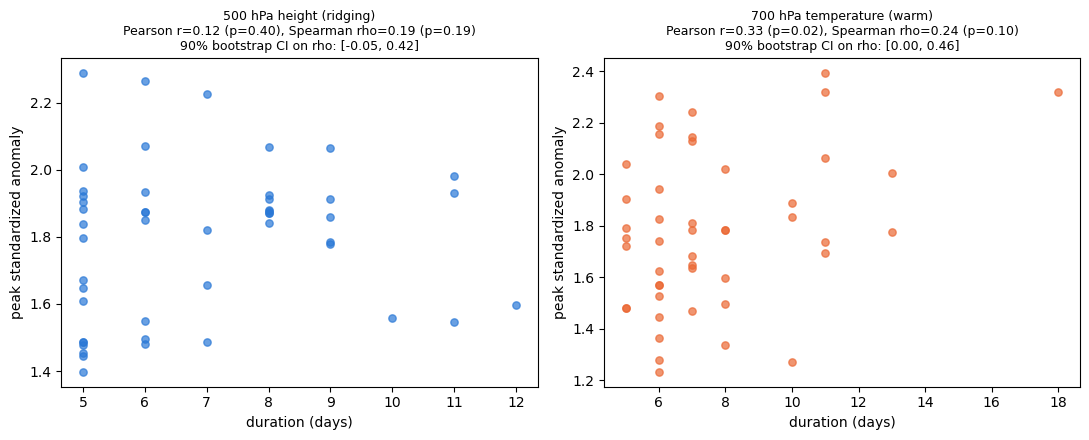

In [3]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (col, label) in zip(axes, VARS):
    sub = events[events.variable == label]
    x, y = sub.duration_days.values, sub.peak_sanom.values
    r_pearson, p_pearson = pearsonr(x, y)
    rho, p_spearman = spearmanr(x, y)
    lo, hi = bootstrap_spearman_ci(x, y)
    ax.scatter(x, y, s=28, alpha=0.7, color=COLOR[label])
    ax.set_xlabel('duration (days)')
    ax.set_ylabel('peak standardized anomaly')
    ax.set_title(f'{label}\nPearson r={r_pearson:.2f} (p={p_pearson:.2f}), '
                 f'Spearman rho={rho:.2f} (p={p_spearman:.2f})\n'
                 f'90% bootstrap CI on rho: [{lo:.2f}, {hi:.2f}]', fontsize=9)
    print(f'{label}: n={len(sub)}, duration vs peak_sanom -- '
          f'Pearson r={r_pearson:.3f} (p={p_pearson:.3f}), '
          f'Spearman rho={rho:.3f} (p={p_spearman:.3f}), 90% CI [{lo:.3f}, {hi:.3f}]')
plt.tight_layout()
plt.show()


In [4]:
print('Duration vs MEAN standardized anomaly (not just peak):')
for col, label in VARS:
    sub = events[events.variable == label]
    x, y = sub.duration_days.values, sub.mean_sanom.values
    rho, p = spearmanr(x, y)
    lo, hi = bootstrap_spearman_ci(x, y)
    print(f'  {label}: n={len(sub)}, Spearman rho={rho:.3f} (p={p:.3f}), 90% CI [{lo:.3f}, {hi:.3f}]')


Duration vs MEAN standardized anomaly (not just peak):


  500 hPa height (ridging): n=48, Spearman rho=0.071 (p=0.631), 90% CI [-0.179, 0.315]


  700 hPa temperature (warm): n=47, Spearman rho=0.015 (p=0.918), 90% CI [-0.227, 0.259]


## 3. Does onset month predict duration?

`CA_snowmelt_april_vs_janmar_match_test.ipynb` already found match-rate and
persistence differences by season (citing Guo and He's reported spring-and-winter
persistence peak). Cheap to check directly against duration here using the same
event table -- small per-month samples, so Kruskal-Wallis (rank-based, no normality
assumption) rather than a parametric ANOVA, and read as indicative given the group
sizes.

500 hPa height (ridging): Kruskal-Wallis across onset months with n>=3, p=0.355
700 hPa temperature (warm): Kruskal-Wallis across onset months with n>=3, p=0.075


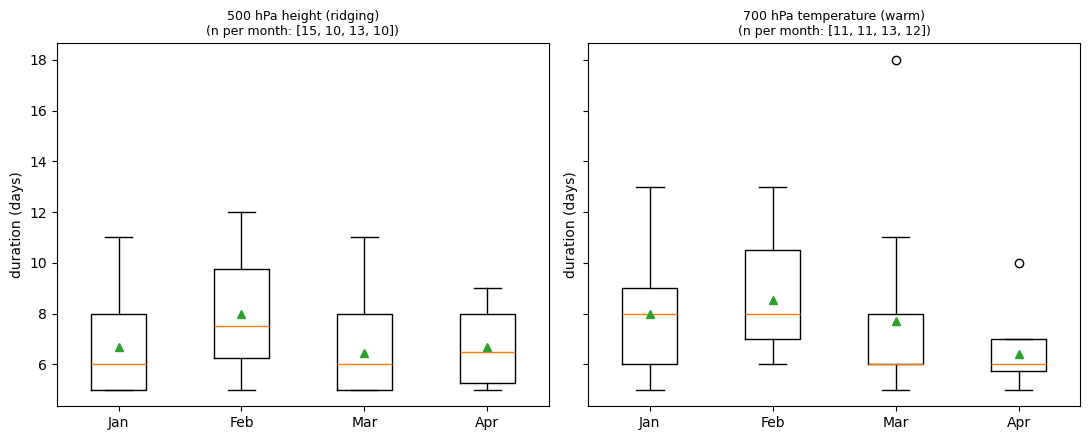

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
MONTH_NAMES = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr'}
for ax, (col, label) in zip(axes, VARS):
    sub = events[events.variable == label]
    by_month = [sub.loc[sub.onset_month == m, 'duration_days'].values for m in [1, 2, 3, 4]]
    ax.boxplot(by_month, tick_labels=[MONTH_NAMES[m] for m in [1, 2, 3, 4]], showmeans=True)
    ns = [len(g) for g in by_month]
    ax.set_title(f'{label}\n(n per month: {ns})', fontsize=9)
    ax.set_ylabel('duration (days)')
    groups_nonempty = [g for g in by_month if len(g) >= 3]
    if len(groups_nonempty) >= 2:
        stat, p = kruskal(*groups_nonempty)
        print(f'{label}: Kruskal-Wallis across onset months with n>=3, p={p:.3f}')
    else:
        print(f'{label}: too few months with n>=3 events for Kruskal-Wallis')
plt.tight_layout()
plt.show()


## 4. Does local ridge/warm-spell spatial structure differ by duration?

Splits events at the **median duration** into "long" and "short" halves (a tercile
split was considered but leaves too few events per group given n=47-48 total), and
builds an event-mean composite anomaly field for each half over the gridded CA box
-- same `gridpoint_climatology` / event-mean-field / block-bootstrap-CI machinery as
the headline notebook's own Section 5 spatial check (`event_mean_fields`,
`bootstrap_composite_ci`), just grouping by duration instead of
matched/unmatched-heat-wave status. Uses the already-fetched `z500_t700_ca_<year>.nc`
for all 36 years -- no new data.

In [6]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
ds = lib.open_yearly_dataset(files, missing_hint='Run get_z500_t700_ca.py first.')
time_index = pd.to_datetime(ds.time.values)
lon_plot = np.where(ds.longitude.values > 180, ds.longitude.values - 360, ds.longitude.values)


def gridpoint_climatology(da, window=CLIM_WINDOW):
    vals = da.load().values
    clim_mean = lib.climatology_dict(time_index, vals, window, compute_std=False)
    return vals - lib.lookup_climatology(time_index, clim_mean)


def event_mean_fields(events_sub, grid_anom):
    fields = []
    for _, row in events_sub.iterrows():
        mask = (time_index.date >= row.start_date) & (time_index.date <= row.end_date)
        fields.append(grid_anom[mask].mean(axis=0))
    return np.stack(fields)


z500_grid_anom = gridpoint_climatology(ds['z500'])
t700_grid_anom = gridpoint_climatology(ds['t700'])
grid_anoms = {'z500': z500_grid_anom, 't700': t700_grid_anom}

split_info = {}
for col, label in VARS:
    sub = events[events.variable == label].copy()
    med = sub.duration_days.median()
    sub['group'] = np.where(sub.duration_days >= med, 'long', 'short')
    split_info[col] = (sub, med)
    print(f'{label}: median duration = {med:.1f} days -- '
          f'{(sub.group == "long").sum()} long (>= median), {(sub.group == "short").sum()} short (< median)')


500 hPa height (ridging): median duration = 6.0 days -- 31 long (>= median), 17 short (< median)
700 hPa temperature (warm): median duration = 7.0 days -- 26 long (>= median), 21 short (< median)


Bootstrap CI for the composite maps reuses the same block-over-events resampling
as the headline notebook's spatial check -- resampling events, not days, since days
within one event are highly autocorrelated.

In [7]:
def bootstrap_composite_ci(event_fields, n_boot=N_BOOT, rng=rng):
    n_events = event_fields.shape[0]
    boot = np.empty((n_boot,) + event_fields.shape[1:])
    for b in range(n_boot):
        idx = rng.integers(0, n_events, size=n_events)
        boot[b] = event_fields[idx].mean(axis=0)
    return np.percentile(boot, [2.5, 97.5], axis=0)


composites, not_sig_masks, amplitudes, event_counts = {}, {}, {}, {}
for col, label in VARS:
    sub, med = split_info[col]
    for name in ['long', 'short']:
        grp = sub[sub.group == name]
        fields = event_mean_fields(grp, grid_anoms[col])
        composite = fields.mean(axis=0)
        ci_lo, ci_hi = bootstrap_composite_ci(fields)
        composites[(col, name)] = composite
        not_sig_masks[(col, name)] = (ci_lo <= 0) & (ci_hi >= 0)
        amplitudes[(col, name)] = np.abs(composite).max()
        event_counts[(col, name)] = len(grp)
        print(f'{label} {name} (n={len(grp)}): domain-mean={composite.mean():.3f}, '
              f'peak amplitude={amplitudes[(col, name)]:.3f}, '
              f'fraction not significant={not_sig_masks[(col, name)].mean():.2f}')


500 hPa height (ridging) long (n=31): domain-mean=127.694, peak amplitude=151.887, fraction not significant=0.00
500 hPa height (ridging) short (n=17): domain-mean=126.298, peak amplitude=146.216, fraction not significant=0.00


700 hPa temperature (warm) long (n=26): domain-mean=5.432, peak amplitude=6.617, fraction not significant=0.00


700 hPa temperature (warm) short (n=21): domain-mean=5.262, peak amplitude=6.317, fraction not significant=0.00


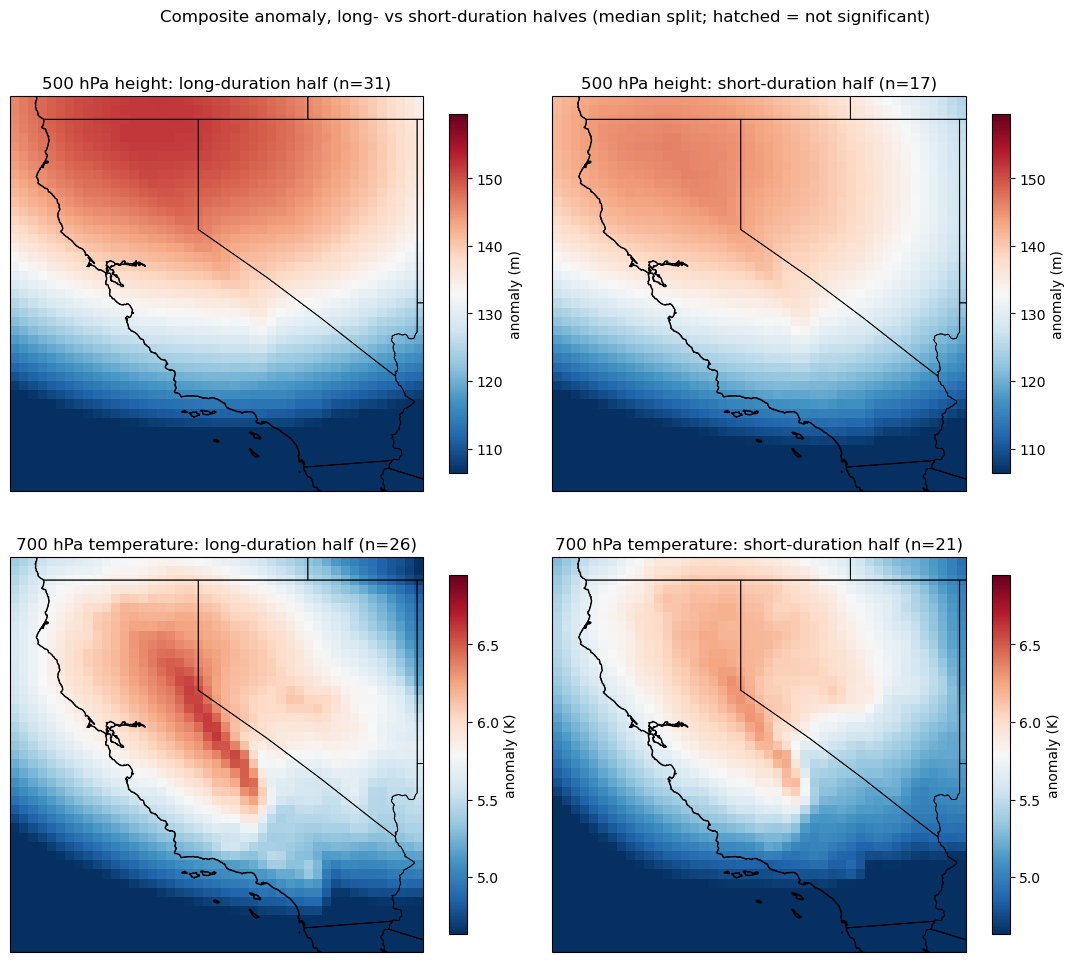

In [8]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, axes = plt.subplots(2, 2, figsize=(11, 10), subplot_kw={'projection': ccrs.PlateCarree()})
row_info = [('z500', '500 hPa height', 'm'), ('t700', '700 hPa temperature', 'K')]
for i, (col, var_label, units) in enumerate(row_info):
    both = np.concatenate([composites[(col, 'long')].ravel(), composites[(col, 'short')].ravel()])
    vmax = np.abs(both).max() * 1.05
    for j, name in enumerate(['long', 'short']):
        ax = axes[i, j]
        pcm = ax.pcolormesh(lon_plot, ds.latitude.values, composites[(col, name)], cmap='RdBu_r',
                             vmin=vmax * 2 / 3., vmax=vmax, shading='auto', transform=ccrs.PlateCarree())
        ax.contourf(lon_plot, ds.latitude.values, not_sig_masks[(col, name)].astype(int), levels=[0.5, 1.5],
                    colors='none', hatches=['...'], transform=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE)
        ax.add_feature(cfeature.STATES, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.6)
        ax.set_title(f'{var_label}: {name}-duration half (n={event_counts[(col, name)]})')
        fig.colorbar(pcm, ax=ax, shrink=0.75, label=f'anomaly ({units})')
fig.suptitle('Composite anomaly, long- vs short-duration halves (median split; hatched = not significant)', y=1.0)
plt.tight_layout()
plt.show()


## 5. Conclusion

**None of the three cheap, full-record angles explain why duration varies -- which is
itself the useful result.** This is the first time this project has tested
persistence drivers against the full 36-year sample (n=47-48) rather than a single
year's 4 episodes, and all three come back null or too weak to trust:

- **Peak intensity does not robustly predict duration.** Z500: Spearman rho=0.19
  (p=0.19, 90% CI [-0.05, 0.42], includes zero). T700: Pearson r=0.33 (p=0.022) looks
  significant, but the more outlier-robust Spearman rho=0.24 is not (p=0.10, 90% CI
  [0.01, 0.46] -- barely excludes zero at one edge). Given this project's established
  preference for rank-based statistics over Pearson on exactly this kind of
  skewed/outlier-prone climate data (Theil-Sen over OLS throughout), the honest read
  is "weak and inconsistent," not "T700 shows a real effect" -- likely driven by one
  or two long, intense episodes (e.g. the 18-day March 2004 T700 event) rather than a
  general relationship.
- **Mean (sustained) intensity shows no relationship at all** -- Z500 rho=0.07
  (p=0.63), T700 rho=0.02 (p=0.92). If anything linked intensity to persistence it
  would show up here first; it doesn't.
- **Onset month doesn't predict duration** -- Z500 Kruskal-Wallis p=0.36 (null);
  T700 p=0.075 (marginal, not significant, but close enough to flag rather than
  dismiss outright if a future pass wants to revisit it with more data).
- **Local spatial structure within the CA box is essentially identical between
  long- and short-duration halves.** Z500: domain-mean anomaly 127.7 vs. 126.3 (long
  vs. short, ~1% apart), peak amplitude 151.9 vs. 146.2 (~4% apart). T700: 5.43 vs.
  5.26 domain-mean (~3% apart), 6.62 vs. 6.32 peak (~5% apart). Both groups'
  composites are themselves robustly nonzero (0% of the domain inside the 95%
  bootstrap CI around zero, as expected for real detected ridge/warm events) --- but
  the *difference between the two groups* is well within what a few-percent sampling
  wobble would produce at these group sizes (n=31/17 Z500, n=26/21 T700). No formal
  between-group difference test was run (would need to bootstrap the composite
  *difference* directly, not just each group's own departure from zero) -- flagged
  here rather than silently assumed, since the numbers are close enough that eyeballing
  isn't a substitute for that test if this thread gets revisited.

**What this changes about the open mechanism question.** It doesn't answer "why does
persistence vary" -- but it now rules out, with real statistical power for the first
time (not a 4-episode case study), the three simplest possible explanations: that
longer episodes are just stronger ones, that they cluster in a particular month, or
that they look structurally different within the CA box itself. Combined with the
upstream-mechanism notebooks' three null upstream diagnostics against the 2026
case study, the honest state of the evidence is: duration is not explained by
anything *local* to the CA box or by simple onset timing, which is consistent with
(does not prove, but is consistent with) the original upstream-precursor hypothesis
-- the explanation, if there is one, most likely really is upstream, and finding it
needs the sample size this notebook just demonstrated matters (47-48 events, not 4).

**What a full-record upstream-precursor test would cost.** `upstream_pacific_2026.nc`
is 325 MB and `upstream_pv_theta_2026.nc` is 1.8 GB for one year; only 2026 has ever
been fetched. Extending either to the full 1990-2025 record (35 more years) is
roughly **+11 GB** (`upstream_pacific`) and **+63 GB** (`upstream_pv_theta`) of new
storage on `/glade/campaign`, plus the compute cost of 35 more
`ProcessPoolExecutor`-based multi-file RDA archive reads per year (the same pattern
`get_z500_t700_ca.py` already uses, but over a much wider Pacific-North America
domain and, for the PV/theta variant, 11 vertical levels instead of 1) -- likely
several hours of wall-clock time even parallelized, probably best run as a PBS job
array like the existing `job_array_get_z500_t700_ca.pbs`. That's a real resource
commitment, not a quick follow-up; worth doing given what this notebook found, but a
decision for the project to make deliberately rather than something to launch as a
side effect of this analysis.